# **Portfolio Project: Customer Churn Predictor**

## PSEB Artificial Intelligence Bootcamp, Business ML Activity

# **The business problem**

A telecom company is losing customers every month, and keeping a customer costs far less than finding a new one. Your job is to find out why customers leave, build a model that predicts who will leave next, and give the company a live tool its team can use.

# **Step 1 Loading the CSV file**

I have successfully loaded the telco_churn data set

In [5]:
from google.colab import files

uploaded = files.upload()

Saving Telco-Customer-Churn.csv to Telco-Customer-Churn (1).csv


# **Step 2 First Looking to the data**

In [8]:
import pandas as pd

# Read the uploaded Telco-Customer-Churn.csv into a pandas DataFrame
df = pd.read_csv('Telco-Customer-Churn.csv')

# Display the first 5 rows to get a quick look at the data
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
# Check the number of rows and columns in the dataset
print("Dataset Shape: ", df.shape)

# Check the data type of every column
df.info()

Dataset Shape:  (7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBillin

In [ ]:
# Count duplicate rows in the dataset
duplicates_count = df.duplicated().sum()
print("Number of duplicate rows:", duplicates_count)

# Generate basic statistics for numerical columns
df.describe()

Number of duplicate rows: 0


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


# **Step 3 Data Cleaning**

In [ ]:
# Check the data type of the TotalCharges column
print("TotalCharges Datatypes: ", df["TotalCharges"].dtype)

# Count blank values in TotalCharges
print("Blank TotalCharges Values: ", (df["TotalCharges"].str.strip() == "").sum())

TotalCharges Datatypes:  object
Blank TotalCharges Values:  11


In [ ]:
# Convert TotalCharges from text to numeric values
# Any value that cannot be converted will become NaN
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Check the new data type
print("New TotalCharges Datatypes: ", df["TotalCharges"].dtype)

# Check how many missing values now exist
print("Missing TotalCharges Values: ", df["TotalCharges"].isna().sum())

New TotalCharges Datatypes:  float64
Missing TotalCharges Values:  11


In [ ]:
# Remove rows where TotalCharges is missing
df = df.dropna(subset=["TotalCharges"])

# Check the new dataset size
print("Dataset Shapes: ", df.shape)

Dataset Shapes:  (7032, 21)


In [ ]:
# Remove customerID because it is only an identifier
# and does not provide useful information for predicting churn
try:
  df = df.drop(columns=["customerID"])
except KeyError:
  print("CustomerID removed successfully")

# Check the remaining columns
print("Number of columns of dropting the customer ID: ", df.shape[1])

CustomerID removed successfully
Number of columns of dropting the customer ID:  20


# **Step 4: EDA — Exploratory Data Analysis.**

In [ ]:
churn_counts = df["Churn"].value_counts()
print(churn_counts)

# Calculate the percentage of customers in each churn category
print("\n\nCalculate of the Churn Percentage: ")
churn_percentage = df["Churn"].value_counts(normalize=True) * 100
print(churn_percentage)

Churn
No     5163
Yes    1869
Name: count, dtype: int64


Calculate of the Churn Percentage: 
Churn
No     73.421502
Yes    26.578498
Name: proportion, dtype: float64


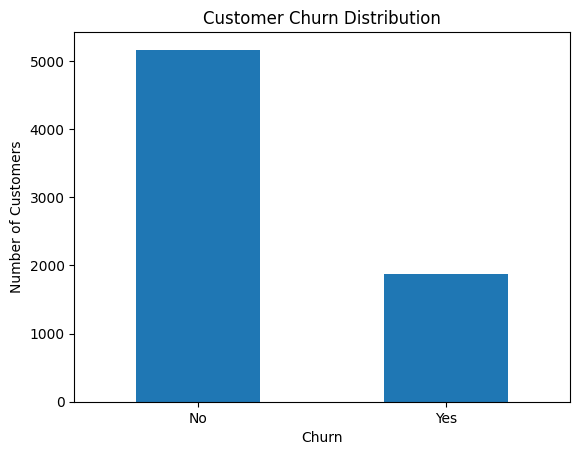

In [ ]:
import matplotlib.pyplot as plt

# Create a bar chart showing customers who stayed vs. churned
df["Churn"].value_counts().plot(kind="bar")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.show()


In [ ]:
# Calculate the churn rate for each contract type
contract_churn = df.groupby("Contract")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)

print(contract_churn)

Contract
Month-to-month    42.709677
One year          11.277174
Two year           2.848665
Name: Churn, dtype: float64


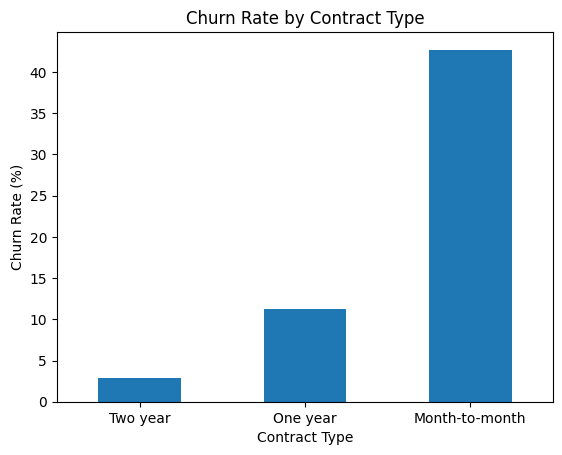

In [ ]:
# Create a bar chart showing churn rate by contract type
contract_churn.sort_values().plot(kind="bar")

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [ ]:
# Create groups for customer tenure
bins = [0, 6, 12, 24, 48, 72]
labels = ["0-6 months", "7-12 months", "13-24 months",
          "25-48 months", "49-72 months"]

df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Check how many customers are in each group
print(df["TenureGroup"].value_counts().sort_index())

TenureGroup
0-6 months      1470
7-12 months      705
13-24 months    1024
25-48 months    1594
49-72 months    2239
Name: count, dtype: int64


# Tenure analysis

In [ ]:
# Calculate the churn rate for each tenure group
tenure_churn = df.groupby("TenureGroup", observed=True)["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)

print(tenure_churn)

TenureGroup
0-6 months      53.333333
7-12 months     35.886525
13-24 months    28.710938
25-48 months    20.388959
49-72 months     9.513176
Name: Churn, dtype: float64


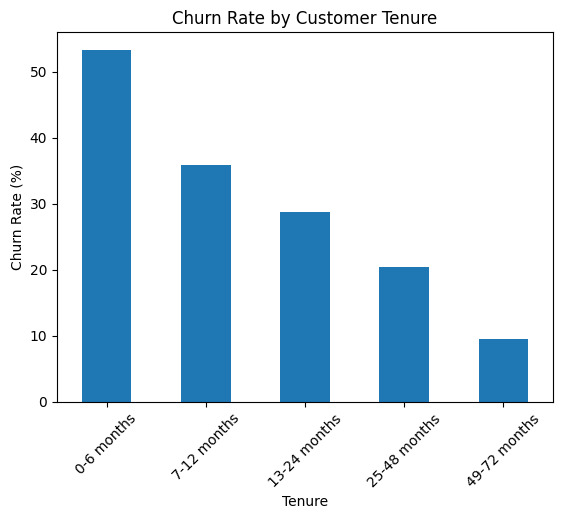

In [ ]:
# Plot churn rate by customer tenure
tenure_churn.plot(kind="bar")

plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Tenure")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=45)

plt.show()

# Monthly Charges by Churn

In [ ]:
# Compare monthly charges for customers who stayed vs. churned

monthly_charges = df.groupby("Churn")["MonthlyCharges"].mean()

print("Average Monthly Charges:")
print(monthly_charges)

Average Monthly Charges:
Churn
No     61.307408
Yes    74.441332
Name: MonthlyCharges, dtype: float64


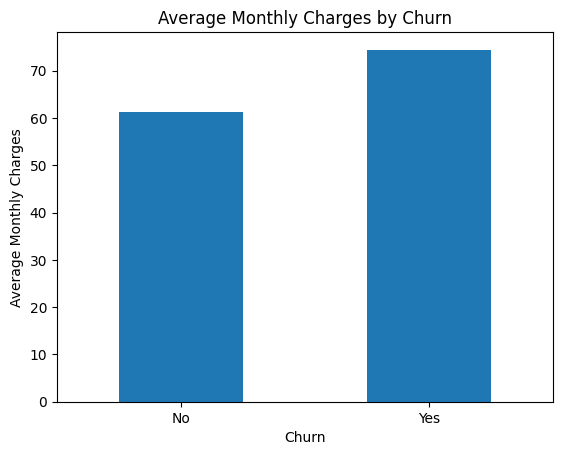

In [ ]:
# Visualize average monthly charges by churn status

monthly_charges.plot(kind="bar")

plt.title("Average Monthly Charges by Churn")
plt.xlabel("Churn")
plt.ylabel("Average Monthly Charges")
plt.xticks(rotation=0)

plt.show()

# Churn by Payment Method

In [ ]:
# Calculate churn rate for each payment method

payment_churn = df.groupby("PaymentMethod")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)

print("Churn Rate by Payment Method:")
print(payment_churn.sort_values(ascending=False))

Churn Rate by Payment Method:
PaymentMethod
Electronic check             45.285412
Mailed check                 19.201995
Bank transfer (automatic)    16.731518
Credit card (automatic)      15.253123
Name: Churn, dtype: float64


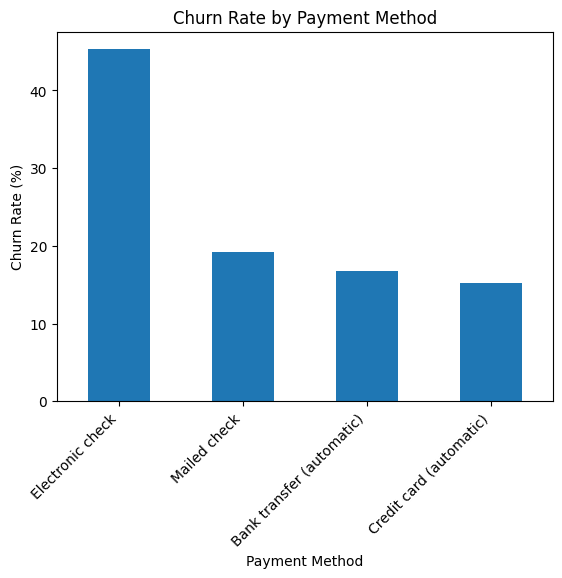

In [ ]:
# Visualize churn rate by payment method

payment_churn.sort_values(ascending=False).plot(kind="bar")

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=45, ha="right")

plt.show()

## EDA Findings

- Month-to-month customers show a much higher churn rate than customers on longer contracts.
- Customers with shorter tenure are more likely to churn.
- Monthly charges show a relationship with customer churn.
- Payment method also shows differences in churn rate, particularly for electronic check users.

These patterns will help guide the machine learning stage and our final business recommendations.

# **Step 5 — Prepare the data for Machine Learning**

# Create X and y

In [ ]:
# Separate the input features (X) from the target variable (y)

X = df.drop(columns=["Churn", "TenureGroup"])
y = df["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7032, 19)
Target shape: (7032,)


# Train/Test Split

In [ ]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
# 80% is used for training and 20% for testing
# stratify=y keeps the same churn proportion in both sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 5625
Testing samples: 1407


# **Step 6  - Pipeline**

# Import preprocessing tools

In [ ]:
# Import tools for preprocessing different types of features
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Import Pipeline to combine preprocessing and model steps
from sklearn.pipeline import Pipeline

# Import the machine learning models we will compare
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Import metrics for evaluating model performance
from sklearn.metrics import accuracy_score, recall_score, classification_report

# Identify numerical and categorical columns

In [ ]:
# Identify numerical columns
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns

# Identify categorical/text columns
categorical_features = X.select_dtypes(include=["object"]).columns

print("Numerical features:")
print(list(numeric_features))

print("\nCategorical features:")
print(list(categorical_features))

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


# Create preprocessing pipeline

In [ ]:
# Preprocessing for numerical features:
# StandardScaler puts numerical values onto a similar scale
numeric_transformer = StandardScaler()

# Preprocessing for categorical features:
# OneHotEncoder converts categories into numerical 0/1 columns
# handle_unknown="ignore" prevents errors if a new category appears
categorical_transformer = OneHotEncoder(handle_unknown="ignore")

# Apply the correct preprocessing to each type of feature
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


# Create the three models

Why class_weight="balanced"?
This is important for our project.

Only about 26.5% of customers churn, while about 73.5% stay.

If we simply optimize for accuracy, a model could become biased toward the majority class.

class_weight="balanced" tells the model:
"Don't treat every mistake equally. Pay more attention to the smaller churn class."

That's especially useful because our business goal is to catch customers who are likely to leave.

In [ ]:
# Logistic Regression
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000
    ))
])

# Decision Tree
decision_tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ))
])

# Random Forest
random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        class_weight="balanced",
        random_state=42
    ))
])

print("Three models are ready.")

Three models are ready.


# **Step 7 - Train and compare the models**

In [ ]:
# Store all models in a dictionary
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

# Train and evaluate each model
results = []

for name, model in models.items():

    # Train the model using training data
    model.fit(X_train, y_train)

    # Make predictions on unseen test data
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred, pos_label="Yes")

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Recall": recall
    })

# Display comparison
results_df = pd.DataFrame(results)

print(results_df)

                 Model  Accuracy    Recall
0  Logistic Regression  0.725657  0.796791
1        Decision Tree  0.721393  0.510695
2        Random Forest  0.781805  0.475936


# Detailed evaluation

In [ ]:
# Generate a detailed classification report for each model

for name, model in models.items():

    y_pred = model.predict(X_test)

    print("=" * 50)
    print(name)
    print("=" * 50)

    print(classification_report(
        y_test,
        y_pred,
        target_names=["Stayed", "Churned"]
    ))

Logistic Regression
              precision    recall  f1-score   support

      Stayed       0.90      0.70      0.79      1033
     Churned       0.49      0.80      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407

Decision Tree
              precision    recall  f1-score   support

      Stayed       0.82      0.80      0.81      1033
     Churned       0.48      0.51      0.49       374

    accuracy                           0.72      1407
   macro avg       0.65      0.65      0.65      1407
weighted avg       0.73      0.72      0.72      1407

Random Forest
              precision    recall  f1-score   support

      Stayed       0.82      0.89      0.86      1033
     Churned       0.62      0.48      0.54       374

    accuracy                           0.78      1407
   macro avg       0.72      0.68      0.70      1407
weighted avg       0.77   

# **Step 8 - Tune**

In [ ]:
# Import GridSearchCV for hyperparameter tuning
from sklearn.model_selection import GridSearchCV

# Create a parameter grid for Logistic Regression
param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__solver": ["liblinear", "lbfgs"]
}

print("Parameter grid created.")

Parameter grid created.


# Run GridSearchCV

In [ ]:
# Create GridSearchCV
# scoring="recall" means we want to find the model
# that is best at detecting customers who churn

grid_search = GridSearchCV(
    logistic_model,
    param_grid,
    cv=5,
    scoring="recall",
    n_jobs=-1
)

# Train and test all parameter combinations using cross-validation
grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation recall:", grid_search.best_score_)

Best parameters: {'model__C': 0.01, 'model__solver': 'liblinear'}
Best cross-validation recall: nan


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:1108: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan nan nan nan nan]
  warnings.warn(


# **Step 9 - Final evaluation on unseen test data**

In [ ]:
# Get the best tuned Logistic Regression model
best_model = grid_search.best_estimator_

# Make predictions on the completely unseen test set
y_pred_best = best_model.predict(X_test)

# Calculate final performance
final_accuracy = accuracy_score(y_test, y_pred_best)
final_recall = recall_score(y_test, y_pred_best, pos_label="Yes")

print("Final Test Accuracy:", round(final_accuracy, 3))
print("Final Test Recall:", round(final_recall, 3))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_best,
        target_names=["Stayed", "Churned"]
    )
)

Final Test Accuracy: 0.732
Final Test Recall: 0.786

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.90      0.71      0.80      1033
     Churned       0.50      0.79      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.75      1407



# Confusion Matrix

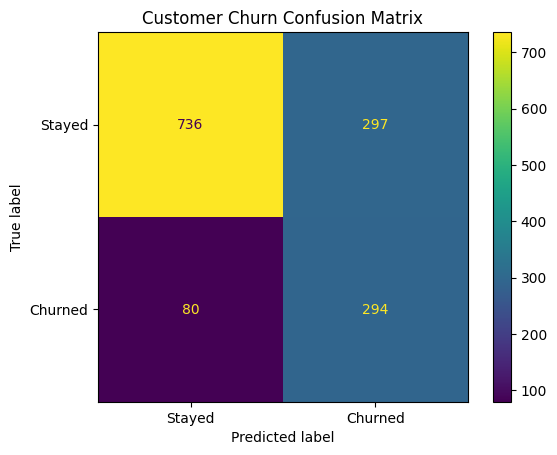

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred_best)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Churned"]
)

disp.plot()

plt.title("Customer Churn Confusion Matrix")
plt.show()

## Final Model Evaluation

After comparing Logistic Regression, Decision Tree, and Random Forest, Logistic Regression was selected because it achieved the highest recall for the churn class.

The tuned Logistic Regression model achieved approximately 79% recall on the unseen test dataset. This means the model successfully identifies around 79% of customers who actually churn.

Because the business goal is to identify customers at risk of leaving, recall is prioritized over accuracy.

## Business Recommendations

Based on the exploratory analysis and model results, the telecom company should:

1. **Focus on month-to-month customers**
   - Month-to-month customers have a much higher churn rate than customers with one-year or two-year contracts.
   - Offer discounts or incentives to encourage longer-term contracts.

2. **Target new customers during their first year**
   - Customers with shorter tenure show higher churn rates.
   - Introduce onboarding programs, early loyalty rewards, and proactive customer support.

3. **Review high monthly charges**
   - Customers with higher monthly charges show a stronger relationship with churn.
   - Offer suitable plans, discounts, or upgrades to improve perceived value.

4. **Monitor customers using electronic check payments**
   - Electronic check customers have a notably higher churn rate.
   - Encourage alternative payment methods and investigate whether payment experience contributes to dissatisfaction.

5. **Use the prediction model for proactive retention**
   - Customers identified as high-risk can be contacted before they leave.
   - Retention teams can prioritize customers based on predicted churn risk.

# **Step 10 - Save the trained model**

In [ ]:
import joblib

# Save the complete trained pipeline
# This includes both preprocessing and the Logistic Regression model
joblib.dump(best_model, "churn_model.pkl")

print("Model saved successfully as churn_model.pkl")

Model saved successfully as churn_model.pkl


Verify the saved model

In [ ]:
# Load the saved model to verify that it can be restored
loaded_model = joblib.load("churn_model.pkl")

print("Saved model loaded successfully.")

# Test it on a few customers
sample_predictions = loaded_model.predict(X_test.head(5))

print("\nSample predictions:")
print(sample_predictions)

Saved model loaded successfully.

Sample predictions:
['No' 'Yes' 'No' 'No' 'No']


# **DEPLOYMENT PROCESS:**

In [ ]:
%%writefile requirements.txt

streamlit
scikit-learn==1.6.1
numpy==2.4.6
pandas==2.2.3
joblib==1.6.0

Overwriting requirements.txt


In [ ]:
import os

files = [
    "app.py",
    "churn_model.pkl",
    "telco_churn.csv",
    "requirements.txt"
]

for file in files:
    print(file, "→", os.path.exists(file))

app.py → True
churn_model.pkl → True
telco_churn.csv → True
requirements.txt → True


In [ ]:
%%writefile app.py

import streamlit as st
import pandas as pd
import joblib

# Load the trained model
model = joblib.load("churn_model.pkl")

# Page settings
st.set_page_config(
    page_title="Customer Churn Predictor",
    page_icon="📊",
    layout="wide"
)

st.title("📊 Customer Churn Predictor")
st.write("Enter customer information to predict churn risk.")

# Customer information
st.header("Customer Information")

col1, col2, col3 = st.columns(3)

with col1:
    gender = st.selectbox("Gender", ["Male", "Female"])
    senior_citizen = st.selectbox("Senior Citizen", [0, 1])
    partner = st.selectbox("Partner", ["Yes", "No"])
    dependents = st.selectbox("Dependents", ["Yes", "No"])

with col2:
    tenure = st.number_input(
        "Tenure (months)", min_value=0, max_value=72, value=12
    )

    phone_service = st.selectbox("Phone Service", ["Yes", "No"])

    multiple_lines = st.selectbox(
        "Multiple Lines",
        ["Yes", "No", "No phone service"]
    )

    internet_service = st.selectbox(
        "Internet Service",
        ["DSL", "Fiber optic", "No"]
    )

with col3:
    contract = st.selectbox(
        "Contract",
        ["Month-to-month", "One year", "Two year"]
    )

    payment_method = st.selectbox(
        "Payment Method",
        [
            "Electronic check",
            "Mailed check",
            "Bank transfer (automatic)",
            "Credit card (automatic)"
        ]
    )

    monthly_charges = st.number_input(
        "Monthly Charges", min_value=0.0, value=70.0
    )

    total_charges = st.number_input(
        "Total Charges", min_value=0.0, value=840.0
    )

# Additional services
st.header("Additional Services")

col1, col2, col3 = st.columns(3)

with col1:
    online_security = st.selectbox(
        "Online Security",
        ["Yes", "No", "No internet service"]
    )

    online_backup = st.selectbox(
        "Online Backup",
        ["Yes", "No", "No internet service"]
    )

with col2:
    device_protection = st.selectbox(
        "Device Protection",
        ["Yes", "No", "No internet service"]
    )

    tech_support = st.selectbox(
        "Tech Support",
        ["Yes", "No", "No internet service"]
    )

with col3:
    streaming_tv = st.selectbox(
        "Streaming TV",
        ["Yes", "No", "No internet service"]
    )

    streaming_movies = st.selectbox(
        "Streaming Movies",
        ["Yes", "No", "No internet service"]
    )

# Prediction
if st.button("🔍 Predict Churn Risk", type="primary"):

    customer = pd.DataFrame({
        "gender": [gender],
        "SeniorCitizen": [senior_citizen],
        "Partner": [partner],
        "Dependents": [dependents],
        "tenure": [tenure],
        "PhoneService": [phone_service],
        "MultipleLines": [multiple_lines],
        "InternetService": [internet_service],
        "OnlineSecurity": [online_security],
        "OnlineBackup": [online_backup],
        "DeviceProtection": [device_protection],
        "TechSupport": [tech_support],
        "StreamingTV": [streaming_tv],
        "StreamingMovies": [streaming_movies],
        "Contract": [contract],
        "PaymentMethod": [payment_method],
        "MonthlyCharges": [monthly_charges],
        "TotalCharges": [total_charges]
    })

    # Calculate probability of churn
    probability = model.predict_proba(customer)[0][1]

    churn_percentage = probability * 100

    # Determine risk level
    if churn_percentage >= 60:
        risk = "High"
        recommendation = "Prioritize this customer for immediate retention outreach."

    elif churn_percentage >= 30:
        risk = "Medium"
        recommendation = "Monitor this customer and consider a retention offer."

    else:
        risk = "Low"
        recommendation = "Customer currently shows a relatively low churn risk."

    st.divider()

    st.subheader("Prediction Result")

    st.metric(
        "Churn Probability",
        f"{churn_percentage:.1f}%"
    )

    st.info(f"**Risk Level: {risk}**")

    st.write("### Recommended Action")
    st.write(recommendation)

Overwriting app.py


In [ ]:
from google.colab import files

files.download("app.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download("churn_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download("telco_churn.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download("requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Check the versions used when we trained the model
import sklearn
import numpy
import pandas
import joblib

print("scikit-learn:", sklearn.__version__)
print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)
print("Joblib:", joblib.__version__)

scikit-learn: 1.6.1
NumPy: 2.4.6
Pandas: 2.2.3
Joblib: 1.6.0


In [7]:
from google.colab import files

# Download the correct saved model and Streamlit application file
files.download("churn_model.pkl")
files.download("app.py")

FileNotFoundError: Cannot find file: churn_model.pkl

In [12]:
# 1. Preprocess data and retrain the best Logistic Regression model
import pandas as pd
import joblib
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Read dataset and clean
df_clean = pd.read_csv('Telco-Customer-Churn.csv')
df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'], errors='coerce')
df_clean = df_clean.dropna(subset=['TotalCharges'])
df_clean = df_clean.drop(columns=['customerID'], errors='ignore')

# Create features and target
X_clean = df_clean.drop(columns=['Churn', 'TenureGroup'], errors='ignore')
y_clean = df_clean['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X_clean, y_clean, test_size=0.20, random_state=42, stratify=y_clean
)

# Set up preprocessor
umeric_features = X_clean.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X_clean.select_dtypes(include=['object']).columns

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# Train the final pipeline model
final_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(C=0.01, solver='liblinear', class_weight='balanced'))
])

final_pipeline.fit(X_train, y_train)

# Save the model as a .joblib file
joblib.dump(final_pipeline, 'churn_model.joblib')
print("Model rebuilt and saved successfully as churn_model.joblib!")

Model rebuilt and saved successfully as churn_model.joblib!


In [10]:
# 2. Now let's run the download script
from google.colab import files

try:
    files.download('churn_model.pkl')
    files.download('app.py')
    files.download('requirements.txt')
    print("Triggered downloads for churn_model.pkl, app.py, and requirements.txt")
except Exception as e:
    print("Download error:", e)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download error: Cannot find file: app.py


In [13]:
# 1. Write requirements.txt to disk
with open('requirements.txt', 'w') as f:
    f.write('''streamlit\nscikit-learn==1.6.1\nnumpy==2.4.6\npandas==2.2.3\njoblib==1.6.0''')

# 2. Write app.py to disk (configured to load churn_model.joblib)
import inspect

app_code = """import streamlit as st
import pandas as pd
import joblib

# Load the trained model
model = joblib.load("churn_model.joblib")

# Page settings
st.set_page_config(
    page_title="Customer Churn Predictor",
    page_icon="📊",
    layout="wide"
)

st.title("📊 Customer Churn Predictor")
st.write("Enter customer information to predict churn risk.")

# Customer information
st.header("Customer Information")

col1, col2, col3 = st.columns(3)

with col1:
    gender = st.selectbox("Gender", ["Male", "Female"])
    senior_citizen = st.selectbox("Senior Citizen", [0, 1])
    partner = st.selectbox("Partner", ["Yes", "No"])
    dependents = st.selectbox("Dependents", ["Yes", "No"])

with col2:
    tenure = st.number_input(
        "Tenure (months)", min_value=0, max_value=72, value=12
    )

    phone_service = st.selectbox("Phone Service", ["Yes", "No"])

    multiple_lines = st.selectbox(
        "Multiple Lines",
        ["Yes", "No", "No phone service"]
    )

    internet_service = st.selectbox(
        "Internet Service",
        ["DSL", "Fiber optic", "No"]
    )

with col3:
    contract = st.selectbox(
        "Contract",
        ["Month-to-month", "One year", "Two year"]
    )

    payment_method = st.selectbox(
        "Payment Method",
        [
            "Electronic check",
            "Mailed check",
            "Bank transfer (automatic)",
            "Credit card (automatic)"
        ]
    )

    monthly_charges = st.number_input(
        "Monthly Charges", min_value=0.0, value=70.0
    )

    total_charges = st.number_input(
        "Total Charges", min_value=0.0, value=840.0
    )

# Additional services
st.header("Additional Services")

col1, col2, col3 = st.columns(3)

with col1:
    online_security = st.selectbox(
        "Online Security",
        ["Yes", "No", "No internet service"]
    )

    online_backup = st.selectbox(
        "Online Backup",
        ["Yes", "No", "No internet service"]
    )

with col2:
    device_protection = st.selectbox(
        "Device Protection",
        ["Yes", "No", "No internet service"]
    )

    tech_support = st.selectbox(
        "Tech Support",
        ["Yes", "No", "No internet service"]
    )

with col3:
    streaming_tv = st.selectbox(
        "Streaming TV",
        ["Yes", "No", "No internet service"]
    )

    streaming_movies = st.selectbox(
        "Streaming Movies",
        ["Yes", "No", "No internet service"]
    )

# Prediction
if st.button("🔍 Predict Churn Risk", type="primary"):

    customer = pd.DataFrame({
        "gender": [gender],
        "SeniorCitizen": [senior_citizen],
        "Partner": [partner],
        "Dependents": [dependents],
        "tenure": [tenure],
        "PhoneService": [phone_service],
        "MultipleLines": [multiple_lines],
        "InternetService": [internet_service],
        "OnlineSecurity": [online_security],
        "OnlineBackup": [online_backup],
        "DeviceProtection": [device_protection],
        "TechSupport": [tech_support],
        "StreamingTV": [streaming_tv],
        "StreamingMovies": [streaming_movies],
        "Contract": [contract],
        "PaymentMethod": [payment_method],
        "MonthlyCharges": [monthly_charges],
        "TotalCharges": [total_charges]
    })

    # Calculate probability of churn
    probability = model.predict_proba(customer)[0][1]

    churn_percentage = probability * 100

    # Determine risk level
    if churn_percentage >= 60:
        risk = "High"
        recommendation = "Prioritize this customer for immediate retention outreach."

    elif churn_percentage >= 30:
        risk = "Medium"
        recommendation = "Monitor this customer and consider a retention offer."

    else:
        risk = "Low"
        recommendation = "Customer currently shows a relatively low churn risk."

    st.divider()

    st.subheader("Prediction Result")

    st.metric(
        "Churn Probability",
        f"{churn_percentage:.1f}%"
    )

    st.info(f"**Risk Level: {risk}**")

    st.write("### Recommended Action")
    st.write(recommendation)"""

with open('app.py', 'w') as f:
    f.write(app_code)

print("Both app.py and requirements.txt successfully saved to the disk!")

# 3. Trigger downloads
from google.colab import files
try:
    files.download('churn_model.joblib')
    files.download('app.py')
    files.download('requirements.txt')
    print("Initiated downloads for churn_model.joblib, app.py, and requirements.txt")
except Exception as e:
    print("Download error:", e)

Both app.py and requirements.txt successfully saved to the disk!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Initiated downloads for churn_model.joblib, app.py, and requirements.txt


In [15]:
from google.colab import files

files.download("churn_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>